# Tests de SGD (`mean_squared_error_sgd`)


## 0. Imports et chargement des données

In [8]:
import time

import matplotlib.pyplot as plt
import numpy as np

from helpers import load_csv_data
from implementations import least_squares, mean_squared_error_sgd
from preprocessing import clean_and_standardize, load_feature_names
from validation import best_threshold, f1_score, split_train_validation

In [9]:
# ~45 s : lecture des CSV
x, _, y, _, _ = load_csv_data("data")
names = load_feature_names("data")

# même coupure 80/20 et même nettoyage que dans run.py
x_tr, x_val, y_tr, y_val = split_train_validation(y, x)
tx_tr, tx_val = clean_and_standardize(x_tr, x_val, names, one_hot=True)
print("tx_tr :", tx_tr.shape, " tx_val :", tx_val.shape)

tx_tr : (262508, 420)  tx_val : (65627, 420)


In [10]:
def pivoted_qr_numpy(matrix):
    """Return R and column pivots with NumPy.

    First reduce the tall input with an orthogonal QR transformation. Column
    pivoting then uses Householder reflections on the small reduced matrix.
    Orthogonal reduction preserves column norms and linear dependence, without
    forming X.T @ X (which would square the condition number).
    """
    r = np.linalg.qr(np.asarray(matrix, dtype=float), mode="r")
    pivots = np.arange(r.shape[1])
    for k in range(min(r.shape)):
        norms = np.linalg.norm(r[k:, k:], axis=0)
        pivot = k + int(np.argmax(norms))
        r[:, [k, pivot]] = r[:, [pivot, k]]
        pivots[[k, pivot]] = pivots[[pivot, k]]
        vector = r[k:, k].copy()
        norm = np.linalg.norm(vector)
        if norm == 0:
            continue
        alpha = -np.copysign(norm, vector[0])
        vector[0] -= alpha
        vector /= np.linalg.norm(vector)
        block = r[k:, k:]
        block -= 2 * np.outer(vector, vector @ block)
        r[k, k] = alpha
        r[k + 1:, k] = 0
    return r, pivots

def f1_validation(w):
    """Seuil choisi sur le train, F1 mesuré sur la validation."""
    if not np.isfinite(w).all():
        return float("nan")
    threshold = best_threshold(y_tr, tx_tr @ w)
    return f1_score(y_val, np.where(tx_val @ w >= threshold, 1, -1))


def run_sgd(tx, gamma, max_iters, seed=1):
    """SGD reproductible : même graine -> mêmes personnes tirées."""
    np.random.seed(seed)
    w, loss = mean_squared_error_sgd(y_tr, tx, np.zeros(tx.shape[1]), max_iters, gamma)
    return w, loss


# Identify independent columns of the preprocessed training matrix only.
# This matches the QR/rank selection in Least_Squares_Ridge_BRFSS.ipynb.
R, piv = pivoted_qr_numpy(tx_tr)
singular_values = np.linalg.svd(R, compute_uv=False)
tolerance = singular_values.max() * max(tx_tr.shape) * np.finfo(float).eps
rank = int(np.sum(singular_values > tolerance))
independent_cols = piv[:rank]
dependent_cols = piv[rank:]

# Solve Least Squares on independent columns to avoid singular normal equations.
tx_tr_ls = tx_tr[:, independent_cols]
w_ls_reduced, loss_ls = least_squares(y_tr, tx_tr_ls)

# Embed the reference weights in the full feature space. This keeps the existing
# evaluation helpers and every SGD experiment on the original one-hot matrices.
w_ls = np.zeros(tx_tr.shape[1])
w_ls[independent_cols] = w_ls_reduced
f1_ls = f1_validation(w_ls)
print(f"Least Squares reference: {rank}/{tx_tr.shape[1]} independent columns; "
      f"loss = {loss_ls:.4f}, validation F1 = {f1_ls:.4f}")


Least Squares reference: 335/420 independent columns; loss = 0.1324, validation F1 = 0.4245


## Test 1 : grille `gamma` × `max_iters`
On cherche la zone où SGD est stable et donne le meilleur F1. `gamma` est testé sur une échelle logarithmique.

Un F1 manquant sur le graphique = SGD a divergé (poids infinis ou `nan`).

In [11]:
gammas = [3e-4, 1e-4, 3e-5, 1e-5]
iters_list = [10_000, 100_000, 300_000, 1_000_000]

results = {}  # (gamma, max_iters) -> (loss, F1)
for gamma in gammas:
    for max_iters in iters_list:
        start = time.time()
        with np.errstate(all="ignore"):  # pas de warnings si ça diverge
            w, loss = run_sgd(tx_tr, gamma, max_iters)
        f1 = f1_validation(w)
        results[(gamma, max_iters)] = (loss, f1)
        print(f"gamma {gamma:.0e}  iters {max_iters:>9}  loss {loss:10.4g}  F1 {f1:.4f}  ({time.time() - start:.1f}s)")

gamma 3e-04  iters     10000  loss     0.1451  F1 0.3625  (0.2s)
gamma 3e-04  iters    100000  loss      304.2  F1 0.1817  (0.9s)
gamma 3e-04  iters    300000  loss  6.682e+10  F1 0.1449  (2.4s)
gamma 3e-04  iters   1000000  loss  2.643e+57  F1 0.1598  (7.9s)
gamma 1e-04  iters     10000  loss     0.1544  F1 0.2828  (0.1s)
gamma 1e-04  iters    100000  loss     0.1371  F1 0.4113  (0.8s)
gamma 1e-04  iters    300000  loss     0.1344  F1 0.4213  (2.4s)
gamma 1e-04  iters   1000000  loss      0.134  F1 0.4142  (7.8s)
gamma 3e-05  iters     10000  loss     0.1748  F1 0.1758  (0.1s)
gamma 3e-05  iters    100000  loss     0.1435  F1 0.3681  (0.8s)
gamma 3e-05  iters    300000  loss      0.137  F1 0.4138  (2.4s)
gamma 3e-05  iters   1000000  loss      0.134  F1 0.4176  (8.0s)
gamma 1e-05  iters     10000  loss     0.2573  F1 0.1144  (0.1s)
gamma 1e-05  iters    100000  loss     0.1543  F1 0.2754  (0.9s)
gamma 1e-05  iters    300000  loss     0.1434  F1 0.3687  (2.5s)
gamma 1e-05  iters   1000

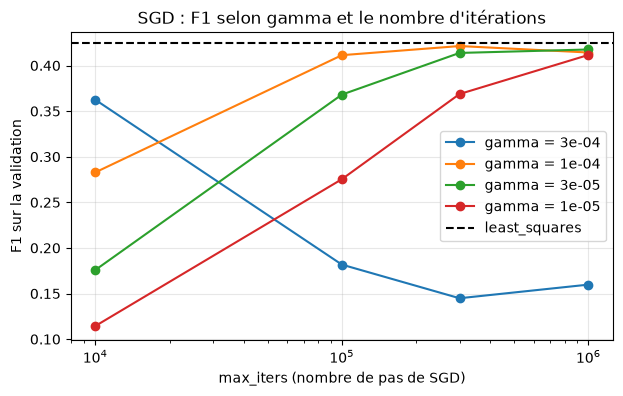

In [12]:
plt.figure(figsize=(7, 4))
for gamma in gammas:
    f1s = [results[(gamma, it)][1] for it in iters_list]
    plt.plot(iters_list, f1s, marker="o", label=f"gamma = {gamma:.0e}")
plt.axhline(f1_ls, color="black", linestyle="--", label="least_squares")
plt.xscale("log")
plt.xlabel("max_iters (nombre de pas de SGD)")
plt.ylabel("F1 sur la validation")
plt.title("SGD : F1 selon gamma et le nombre d'itérations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Test 2 : seed

In [13]:
best_gamma, best_iters = 3e-05, 1000000  # à adapter d'après le test 1

f1s = []
for seed in range(1, 6):
    w, loss = run_sgd(tx_tr, best_gamma, best_iters, seed=seed)
    f1s.append(f1_validation(w))
    print(f"seed {seed} : loss {loss:.4f}  F1 {f1s[-1]:.4f}")
print(f"F1 = {np.nanmean(f1s):.4f} ± {np.nanstd(f1s):.4f}")

seed 1 : loss 0.1340  F1 0.4176
seed 2 : loss 0.1339  F1 0.4207
seed 3 : loss 0.1340  F1 0.4217
seed 4 : loss 0.1340  F1 0.4194
seed 5 : loss 0.1341  F1 0.4202
F1 = 0.4199 ± 0.0014


## Test 3 : chunk

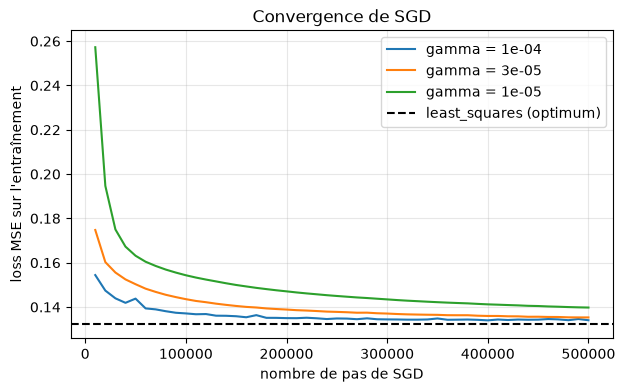

In [14]:
chunk, n_chunks = 10_000, 50
curves = {}
for gamma in [1e-4, 3e-5, 1e-5]:
    np.random.seed(1)
    w, losses = np.zeros(tx_tr.shape[1]), []
    for _ in range(n_chunks):
        with np.errstate(all="ignore"):
            w, loss = mean_squared_error_sgd(y_tr, tx_tr, w, chunk, gamma)
        losses.append(loss)
    curves[gamma] = losses

steps = chunk * np.arange(1, n_chunks + 1)
plt.figure(figsize=(7, 4))
for gamma, losses in curves.items():
    plt.plot(steps, losses, label=f"gamma = {gamma:.0e}")
plt.axhline(loss_ls, color="black", linestyle="--", label="least_squares (optimum)")
plt.ylim(loss_ls * 0.95, loss_ls * 2)
plt.xlabel("nombre de pas de SGD")
plt.ylabel("loss MSE sur l'entraînement")
plt.title("Convergence de SGD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Test 4: train & val


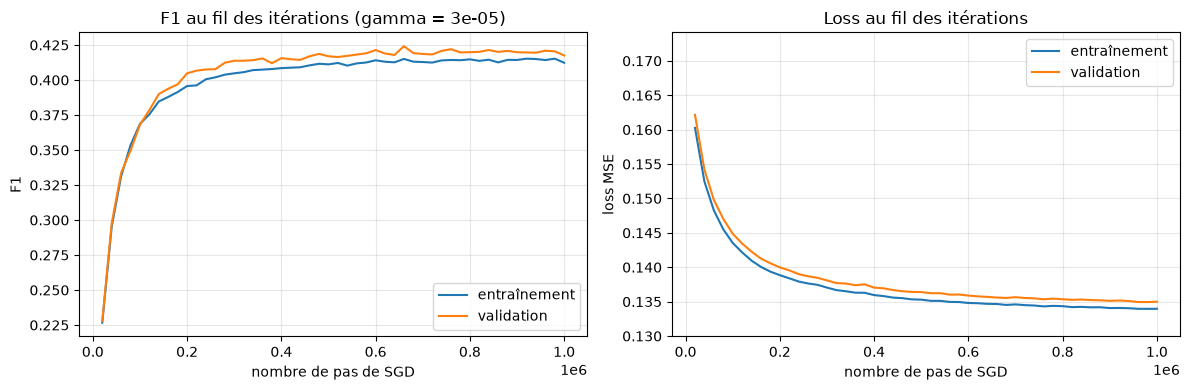

fin : F1 entraînement 0.4123, F1 validation 0.4176


In [15]:
def f1_train_and_val(w, tx_a=None, tx_b=None):
    """F1 sur l'entraînement et sur la validation, avec le seuil choisi sur l'entraînement."""
    tx_a = tx_tr if tx_a is None else tx_a
    tx_b = tx_val if tx_b is None else tx_b
    threshold = best_threshold(y_tr, tx_a @ w)
    f1_tr = f1_score(y_tr, np.where(tx_a @ w >= threshold, 1, -1))
    f1_va = f1_score(y_val, np.where(tx_b @ w >= threshold, 1, -1))
    return f1_tr, f1_va


def mse_loss(y_, tx_, w):
    return np.mean((y_ - tx_ @ w) ** 2) / 2


gamma, chunk, n_chunks = best_gamma, 20_000, 50  # best_gamma vient du test 2
np.random.seed(1)
w = np.zeros(tx_tr.shape[1])
hist = {"f1_tr": [], "f1_val": [], "loss_tr": [], "loss_val": []}
for _ in range(n_chunks):
    with np.errstate(all="ignore"):
        w, _ = mean_squared_error_sgd(y_tr, tx_tr, w, chunk, gamma)
    f1_tr, f1_va = f1_train_and_val(w)
    hist["f1_tr"].append(f1_tr)
    hist["f1_val"].append(f1_va)
    hist["loss_tr"].append(mse_loss(y_tr, tx_tr, w))
    hist["loss_val"].append(mse_loss(y_val, tx_val, w))

steps = chunk * np.arange(1, n_chunks + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(steps, hist["f1_tr"], label="entraînement")
ax1.plot(steps, hist["f1_val"], label="validation")
ax1.set_xlabel("nombre de pas de SGD")
ax1.set_ylabel("F1")
ax1.set_title(f"F1 au fil des itérations (gamma = {gamma:.0e})")
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(steps, hist["loss_tr"], label="entraînement")
ax2.plot(steps, hist["loss_val"], label="validation")
ax2.set_ylim(min(hist["loss_tr"]) * 0.97, min(hist["loss_tr"]) * 1.3)
ax2.set_xlabel("nombre de pas de SGD")
ax2.set_ylabel("loss MSE")
ax2.set_title("Loss au fil des itérations")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"fin : F1 entraînement {hist['f1_tr'][-1]:.4f}, F1 validation {hist['f1_val'][-1]:.4f}")

# Test 5: train curve


n =    1000 : F1 entraînement 0.6203, F1 validation 0.3213
n =    3000 : F1 entraînement 0.4626, F1 validation 0.3738
n =   10000 : F1 entraînement 0.4493, F1 validation 0.3934
n =   30000 : F1 entraînement 0.4223, F1 validation 0.4074
n =  100000 : F1 entraînement 0.4070, F1 validation 0.4120
n =  262508 : F1 entraînement 0.4048, F1 validation 0.4138


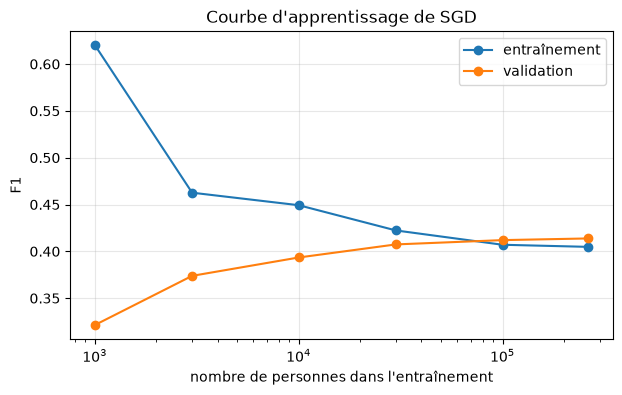

In [16]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, len(y_tr)]
curve_tr, curve_val = [], []
for n in sizes:
    # les lignes de tx_tr sont déjà mélangées (split_train_validation) :
    # les n premières forment un sous-échantillon aléatoire
    tx_n, y_n = tx_tr[:n], y_tr[:n]
    np.random.seed(1)
    with np.errstate(all="ignore"):
        w, _ = mean_squared_error_sgd(y_n, tx_n, np.zeros(tx_n.shape[1]), 300_000, best_gamma)
    threshold = best_threshold(y_n, tx_n @ w)
    curve_tr.append(f1_score(y_n, np.where(tx_n @ w >= threshold, 1, -1)))
    curve_val.append(f1_score(y_val, np.where(tx_val @ w >= threshold, 1, -1)))
    print(f"n = {n:>7} : F1 entraînement {curve_tr[-1]:.4f}, F1 validation {curve_val[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(sizes, curve_tr, marker="o", label="entraînement")
plt.plot(sizes, curve_val, marker="o", label="validation")
plt.xscale("log")
plt.xlabel("nombre de personnes dans l'entraînement")
plt.ylabel("F1")
plt.title("Courbe d'apprentissage de SGD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()